# Lateral PML: isolated structures

A lateral perfectly matched layer (PML) at the edges of a rectangular supercell turns the periodic
solver into one for **isolated** structures: the light scattered towards the neighbouring copies
is absorbed before it reaches them. See `docs/PML.md` for the formulation.

This notebook checks three things at normal incidence:

1. A **uniform stack** under the PML gives exactly the transfer-matrix result (the plane wave is an
   exact mode of the PML'd half-spaces).
2. A **weakly guided slab waveguide**: the effective index of the isolated waveguide is reached in
   a much smaller cell than with the periodic solver, where neighbouring copies couple.
3. An **isolated ridge** on a substrate: the cell-size-independent quantity
   $C = L\,(t_{00} - t_{00}^\text{bg})$ settles in smaller cells than with the periodic solver.

Under a PML the default `modesolver` is `"matexp"` (see `docs/PML.md`); the slab section uses
`"eig"` explicitly, because the layer eigenvalues *are* the waveguide modes.

In [1]:
import math
import torch
import matplotlib.pyplot as plt

from metarcwa import (Config, Factorization, IsotropicMedium, Lattice, Layer, Model, Observables,
                      PML, Solver, Source, Stack)
from metarcwa.model.nn_helpers import CallableModule
from metarcwa.solver.base import build_layersolver

dtype = torch.float64
device = "cuda" if torch.cuda.is_available() else "cpu"
torch.set_default_dtype(dtype)


def medium(eps):
    """Constant-permittivity isotropic medium."""
    return IsotropicMedium(CallableModule(lambda wl: torch.full_like(wl, eps, dtype=torch.complex128)))


def stripe_mask(L, width):
    """Centred stripe of the given width along x, uniform along y."""
    def shape_fn(lattice, nx, ny):
        x = ((torch.arange(nx, dtype=dtype) + 0.5) / nx - 0.5) * L
        return (x.abs() < width / 2).to(dtype)[None, :].expand(ny, nx)
    return CallableModule(shape_fn)


def shade_pml(ax, L, width):
    """Shade the PML bands at both cell edges along x."""
    for x0 in (-L / 2, L / 2 - width):
        ax.axvspan(x0, x0 + width, color="0.5", alpha=0.35, hatch="//", lw=0)
    for xc in (-L / 2 + width / 2, L / 2 - width / 2):
        ax.text(xc, 0.96, "PML", transform=ax.get_xaxis_transform(), ha="center", va="top",
                bbox=dict(fc="white", ec="none", alpha=0.8))


def plot_xz(ax, L, layers, pml_width, nx=400):
    """x-z cross-section of the refractive index; ``layers`` = [(thickness, n_of_x), ...] from top to bottom."""
    x = ((torch.arange(nx, dtype=dtype) + 0.5) / nx - 0.5) * L
    z_top = sum(t for t, _ in layers)
    z_edges, rows = [z_top], []
    for t, n_of_x in layers:
        rows.append(n_of_x(x))
        z_edges.append(z_edges[-1] - t)
    x_edges = torch.linspace(-L / 2, L / 2, nx + 1)
    mesh = ax.pcolormesh(x_edges, torch.tensor(z_edges), torch.stack(rows), cmap="Blues", vmin=1.0)
    plt.colorbar(mesh, ax=ax, label="refractive index")
    shade_pml(ax, L, pml_width)
    ax.set_xlabel("x")
    ax.set_ylabel("z")

## 1. Uniform stack: PML vs transfer matrix

Two films on a glass substrate. With a PML of any strength the specular reflection and
transmission are unchanged.

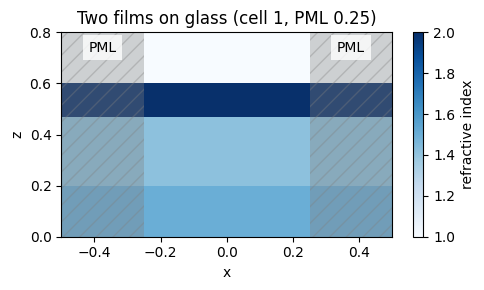

In [2]:
films = [(2.0, 0.13), (2.0 ** 0.5, 0.27)]          # (index, thickness)
n_sub, wvl = 1.5, 0.8

const = lambda n: (lambda x: torch.full_like(x, n))
fig, ax = plt.subplots(figsize=(5, 3))
plot_xz(ax, 1.0, [(0.2, const(1.0))] + [(d, const(n)) for n, d in films] + [(0.2, const(n_sub))], pml_width=0.25)
ax.set_title("Two films on glass (cell 1, PML 0.25)")
plt.tight_layout()
plt.show()

In [3]:
def tmm_normal():
    k0 = 2 * math.pi / wvl
    M = torch.eye(2, dtype=torch.complex128)
    for n, d in films:
        dl = torch.tensor(k0 * n * d)
        M = M @ torch.stack([torch.stack([torch.cos(dl), -1j * torch.sin(dl) / n]),
                             torch.stack([-1j * n * torch.sin(dl), torch.cos(dl)])])
    B, C = M @ torch.tensor([1.0, n_sub], dtype=torch.complex128)
    return float(abs((B - C) / (B + C)) ** 2), float(n_sub * abs(2 / (B + C)) ** 2)


layers = [Layer(medium_solid=medium(n ** 2), thickness=d) for n, d in films]
stack = Stack(incidence=medium(1.0), layers=layers, transmission=medium(n_sub ** 2),
              lattice=Lattice.rectangular(1.0, 1.0), pml=PML(width=0.25))
cfg = Config(dtype=dtype, device=device, nx=32, ny=32, m=4, n=4, truncation="rectangular")
obs = Observables(Solver(Model(stack, Source(wavelength=wvl)), cfg).run())
rs, _ = obs.reflection("s")
ts, _ = obs.transmission("s")

print("TMM          R = %.10f  T = %.10f" % tmm_normal())
print("RCWA + PML   R = %.10f  T = %.10f" % (abs(rs.reshape(-1)[0]) ** 2, n_sub * abs(ts.reshape(-1)[0]) ** 2))

TMM          R = 0.1744969602  T = 0.8255030398
RCWA + PML   R = 0.1744969598  T = 0.8255030226


## 2. Slab waveguide: effective index vs cell size

A slab (index 1.6, width 0.3) in a cladding (index 1.45), uniform along $y$ and $z$, at wavelength 1.
Its evanescent tail decays over $\approx 0.45$, so in small cells it reaches the neighbouring copy.
The patterned layer's eigenvalues $\lambda = j k_z$ give the guided modes, $n_\text{eff} = \operatorname{Im}\lambda$.
The PML is applied along $x$ only. The core is rasterized exactly (pixel 0.0125).

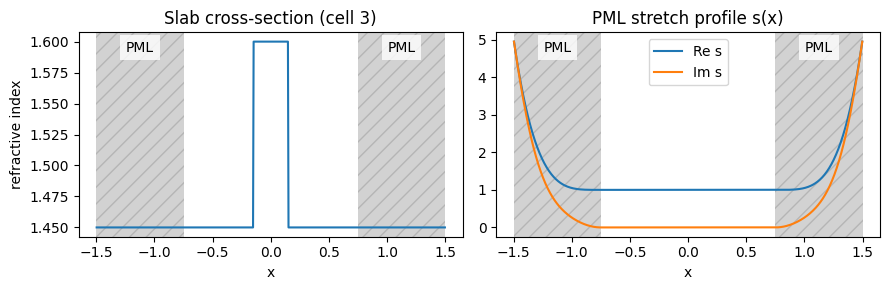

In [4]:
n1, n2, d_core = 1.6, 1.45, 0.3

L, w = 3.0, 0.75
x = ((torch.arange(600, dtype=dtype) + 0.5) / 600 - 0.5) * L
s = PML(width=(w, 0.0)).to(dtype).spec(Lattice.rectangular(L, 1.0).to(dtype), 600, 4).sx

fig, ax = plt.subplots(1, 2, figsize=(9, 3))
ax[0].plot(x, torch.where(x.abs() < d_core / 2, n1, n2))
ax[0].set_ylabel("refractive index")
ax[0].set_title("Slab cross-section (cell 3)")
ax[1].plot(x, s.real, label="Re s")
ax[1].plot(x, s.imag, label="Im s")
ax[1].set_title("PML stretch profile s(x)")
ax[1].legend()
for a in ax:
    shade_pml(a, L, w)
    a.set_xlabel("x")
plt.tight_layout()
plt.show()

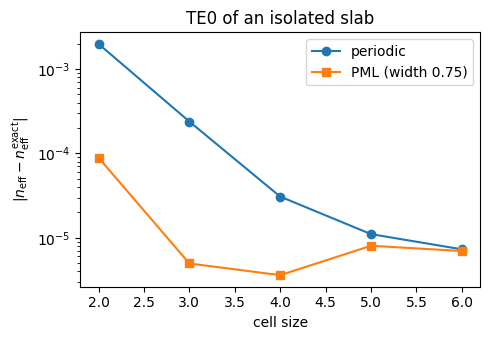

In [5]:
def slab_neff_analytic(pol="TE"):
    """Fundamental mode of a symmetric slab, by bisection."""
    k0 = 2 * math.pi
    ratio = 1.0 if pol == "TE" else (n1 / n2) ** 2
    f = lambda n: (k0 * math.sqrt(n1**2 - n**2) * math.tan(k0 * math.sqrt(n1**2 - n**2) * d_core / 2)
                   - ratio * k0 * math.sqrt(n**2 - n2**2))
    lo = max(n2, math.sqrt(max(n1**2 - (math.pi / (k0 * d_core)) ** 2, 0.0))) + 1e-12
    hi = n1 - 1e-12
    for _ in range(200):
        mid = (lo + hi) / 2
        lo, hi = (mid, hi) if f(mid) > 0 else (lo, mid)
    return (lo + hi) / 2


def slab_neff(L, pml):
    """TE0 effective index of the slab in a cell of size L."""
    M = round(20 * L / 3)
    cfg = Config(dtype=dtype, device=device, nx=round(L / 0.0125), ny=4, m=M, n=0,
                 truncation="rectangular", factorization=Factorization(), modesolver="eig")
    layer = Layer(medium_solid=medium(n1**2), medium_void=medium(n2**2),
                  shape_fn=stripe_mask(L, d_core), thickness=1.0)
    stack = Stack(incidence=medium(1.0), layers=[layer], transmission=medium(1.0),
                  lattice=Lattice.rectangular(L, 1.0), pml=pml)
    spec = Model(stack, Source(wavelength=1.0)).to(dtype=dtype, device=device).spec(cfg.nx, cfg.ny)
    kz = build_layersolver(spec, cfg).prepare(spec.layers[0]).lam.reshape(-1) / 1j
    guided = kz[(kz.real > n2) & (kz.real < n1) & (kz.imag.abs() < 1e-3)]
    return guided[guided.real.argmax()]


exact = slab_neff_analytic("TE")
cells = [2.0, 3.0, 4.0, 5.0, 6.0]
err_pml = [float(abs(slab_neff(L, PML(width=(0.75, 0.0))).real - exact)) for L in cells]
err_per = [float(abs(slab_neff(L, None).real - exact)) for L in cells]

plt.figure(figsize=(5, 3.5))
plt.semilogy(cells, err_per, "o-", label="periodic")
plt.semilogy(cells, err_pml, "s-", label="PML (width 0.75)")
plt.xlabel("cell size")
plt.ylabel(r"$|n_\mathrm{eff} - n_\mathrm{eff}^\mathrm{exact}|$")
plt.title("TE0 of an isolated slab")
plt.legend()
plt.tight_layout()
plt.show()

The periodic solver converges only as the copies separate; with the PML the isolated-waveguide
value is reached at cell size 3, down to the harmonic-truncation floor ($\sim 5\times10^{-6}$).

## 3. Isolated ridge on a substrate

A ridge (index 2, width 0.5, height 0.3) on glass, uniform along $y$, under normal incidence ($s$
polarization), PML along $x$. For an isolated ridge, $C = L\,(t_{00} - t_{00}^\text{bg})$ (the
cell-averaged forward scattering times the cell size) does not depend on the cell size $L$.

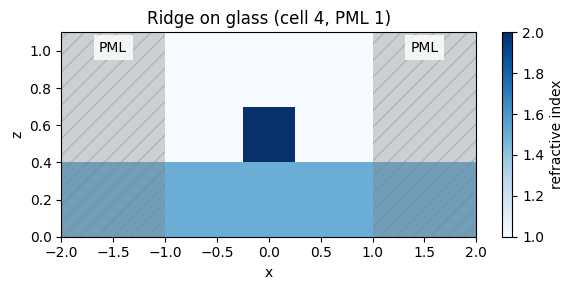

In [6]:
n_ridge, w_ridge, h_ridge, n_glass = 2.0, 0.5, 0.3, 1.5

L = 4.0
ridge = lambda x: torch.where(x.abs() < w_ridge / 2, n_ridge, 1.0)
fig, ax = plt.subplots(figsize=(6, 3))
plot_xz(ax, L, [(0.4, lambda x: torch.ones_like(x)), (h_ridge, ridge), (0.4, lambda x: torch.full_like(x, n_glass))],
        pml_width=1.0)
ax.set_title("Ridge on glass (cell 4, PML 1)")
plt.tight_layout()
plt.show()

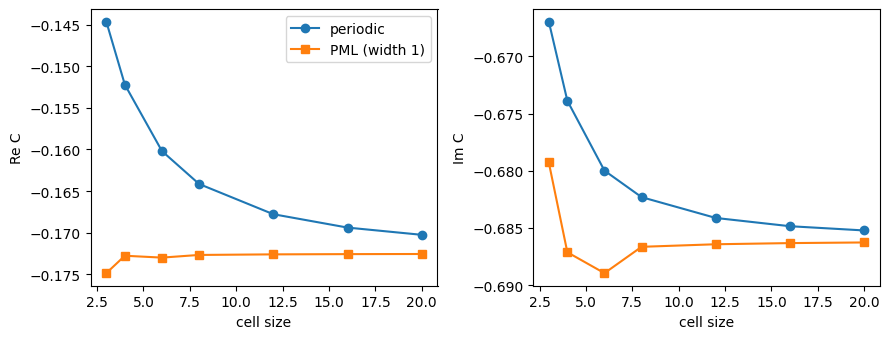

In [7]:
def ridge_t00(L, pml, ridge):
    cfg = Config(dtype=dtype, device=device, nx=128 * int(L), ny=4, m=int(8 * L), n=0,
                 truncation="rectangular", factorization=Factorization())
    layer = Layer(medium_solid=medium(n_ridge**2), medium_void=medium(1.0),
                  shape_fn=stripe_mask(L, w_ridge if ridge else 0.0), thickness=h_ridge)
    stack = Stack(incidence=medium(1.0), layers=[layer], transmission=medium(n_glass**2),
                  lattice=Lattice.rectangular(L, 1.0), pml=pml)
    ts, _ = Observables(Solver(Model(stack, Source(wavelength=1.0)), cfg).run()).transmission("s")
    return ts.reshape(-1)[0]


def ridge_C(L, pml):
    return L * (ridge_t00(L, pml, True) - ridge_t00(L, pml, False))


cells = [3, 4, 6, 8, 12, 16, 20]
C_pml = torch.stack([ridge_C(L, PML(width=(1.0, 0.0))) for L in cells]).cpu()
C_per = torch.stack([ridge_C(L, None) for L in cells]).cpu()

fig, ax = plt.subplots(1, 2, figsize=(9, 3.5))
for a, part, name in ((ax[0], torch.real, "Re C"), (ax[1], torch.imag, "Im C")):
    a.plot(cells, part(C_per), "o-", label="periodic")
    a.plot(cells, part(C_pml), "s-", label="PML (width 1)")
    a.set_xlabel("cell size")
    a.set_ylabel(name)
ax[0].legend()
plt.tight_layout()
plt.show()

Both curves converge to the same limit, the isolated ridge, as they should: as the cell grows,
the copies of the periodic array separate and its result approaches the isolated one, which the PML
computes directly. The difference is the rate. Distance to the PML value at cell size 12:

| Cell size | 3 | 4 | 6 | 8 | 12 |
|---|---|---|---|---|---|
| Periodic | 0.034 | 0.024 | 0.014 | 0.0093 | 0.0053 |
| PML | 0.0075 | 0.0007 | 0.0026 | 0.0002 | 0 |

The periodic error falls roughly as $1/L$ (error $\times L$ goes from $0.10$ to $0.06$): the copies keep coupling through light radiated along the
surface, which fades slowly with distance. Reaching the $\sim 2\times10^{-4}$ of the PML at cell
size 8 would take a periodic cell of well over a hundred wavelengths. The remaining variation of the PML
curve comes mostly from the cell-averaged observable itself, not from PML reflection (see
`docs/PML.md`, "Choosing parameters").